Task 1.1 Get tickers and prices

In [1]:
import pandas as pd
import numpy as np
import requests
import datetime as dt
from io import StringIO
import yfinance as yf

START = "2021-01-01"
END = "2025-01-01"

**Data source**

* yfinance: free, and supplies daily Adj Close, Close and Volume for the S&P 500 shares and for the ^GSPC benchmark, which Tasks 1.1 to 1.4 need.

* auto_adjust=False, so Adj Close and Close are both kept and corporate actions can be checked in 1.2.

1.2 requirement: cached-dataset fallback

In [2]:
#Cached-data fallback settings (used only if live access fails)
import os, json, zipfile, urllib.request
import requests
from io import StringIO
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
CACHE_DIR = "data"
FORCE_CACHE = False   # set True only to test the fallback; keep False for normal runs
CACHE_ZIP_URL = "https://raw.githubusercontent.com/abarni-t/CWK1-SP500-RFM-Abarni/main/cwk1_data.zip"
CACHE_FILES = ["sp500_constituents.csv", "adj_close.csv.gz", "close.csv.gz", "volume.csv.gz",
               "index_adj_close.csv.gz", "snapshot_metadata.json"]

In [3]:
def live_acquire():
    """Primary source: Wikipedia constituent list + Yahoo Finance prices and volume."""
    page = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    page.raise_for_status()
    table = pd.read_html(StringIO(page.text))[0]
    tickers = table["Symbol"].str.replace(".", "-", regex=False).tolist()
    raw = yf.download(tickers, start=START, end=END, auto_adjust=False)
    idx = yf.download("^GSPC", start=START, end=END, auto_adjust=False)
    return {"table": table, "adj": raw["Adj Close"], "close": raw["Close"], "volume": raw["Volume"],
            "index_adj": idx["Adj Close"], "retrieved": dt.date.today()}

def read_wide(name):
    df = pd.read_csv(os.path.join(CACHE_DIR, name), index_col=0, parse_dates=True)
    df.index.name, df.columns.name = "Date", "Ticker"
    return df

def load_cache():
    """Fallback: the saved snapshot in data/, otherwise cwk1_data.zip from the GitHub repository."""
    if not all(os.path.exists(os.path.join(CACHE_DIR, f)) for f in CACHE_FILES):
        urllib.request.urlretrieve(CACHE_ZIP_URL, "cwk1_data.zip")
        zipfile.ZipFile("cwk1_data.zip").extractall(".")
    snap = json.load(open(os.path.join(CACHE_DIR, "snapshot_metadata.json")))
    if (snap["study_start"], snap["study_end_exclusive"]) != (START, END):
        raise ValueError("cached snapshot covers a different study period")
    return {"table": pd.read_csv(os.path.join(CACHE_DIR, "sp500_constituents.csv")),
            "adj": read_wide("adj_close.csv.gz"), "close": read_wide("close.csv.gz"),
            "volume": read_wide("volume.csv.gz"), "index_adj": read_wide("index_adj_close.csv.gz"),
            "retrieved": dt.date.fromisoformat(snap["retrieved"])}

def check_usable(d):
    """yfinance often returns empty columns instead of an error, so check the download actually worked."""
    shares_with_prices = d["adj"].notna().any().sum()
    if len(d["table"]) < 400 or shares_with_prices < 0.9 * len(d["table"]) or d["index_adj"].dropna().empty:
        raise ValueError(f"incomplete download: {len(d['table'])} companies, {shares_with_prices} with prices")

try:
    if FORCE_CACHE:
        raise RuntimeError("FORCE_CACHE is set (fallback test)")
    data = live_acquire()
    check_usable(data)
    DATA_SOURCE = "live: Wikipedia + Yahoo Finance via yfinance"
except NameError:
    raise   # a coding error (e.g. the imports cell was not run), not a data-source failure
except Exception as live_err:
    print("Live acquisition failed:", live_err, "- using the cached dataset")
    try:
        data = load_cache()
        check_usable(data)
    except Exception as cache_err:
        raise RuntimeError(f"No usable data. Live source: {live_err}. Cached source: {cache_err}") from None
    DATA_SOURCE = "cached snapshot (data/ or GitHub cwk1_data.zip)"

table, adj, close, volume, index_adj = (data[k] for k in ["table", "adj", "close", "volume", "index_adj"])
retrieved = data["retrieved"]
run_date = dt.date.today()
print("Data source:", DATA_SOURCE)
print("Data retrieved on:", retrieved, "| Notebook run on:", run_date)
print("Companies listed:", len(table))
table.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['SNDK', 'FDXF', 'Q', 'VYLR', 'HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed

Data source: live: Wikipedia + Yahoo Finance via yfinance
Data retrieved on: 2026-11-23 | Notebook run on: 2026-11-23
Companies listed: 503


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [4]:
tickers = table["Symbol"].str.replace(".", "-", regex=False).tolist()
print("Tickers:", len(tickers))
print(tickers[:5])
print("BRK-B present:", "BRK-B" in tickers)

Tickers: 503
['MMM', 'AOS', 'ABT', 'ABBV', 'ACN']
BRK-B present: True


In [5]:
# Daily prices (Close), adjusted prices (Adj Close) and volume were loaded in the acquisition cell above
print("Adj Close shape:", adj.shape)
print("Close shape:", close.shape)
print("Volume shape:", volume.shape)
adj.head()

Adj Close shape: (1005, 503)
Close shape: (1005, 503)
Volume shape: (1005, 503)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WY,WYNN,XEL,XOM,XYL,XYZ,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009117,125.537125,84.219139,139.149994,97.269707,33.186359,232.029327,485.339996,132.622620,42.189491,...,26.124495,102.852097,54.757385,33.042755,93.015884,221.160004,95.016190,141.603394,378.130005,152.951981
2021-01-05,114.941261,127.089203,85.090012,148.300003,98.473198,33.319485,233.350281,485.690002,134.993149,43.010090,...,26.371325,106.017517,54.223652,34.635181,92.903931,229.750000,95.025154,144.053436,380.570007,154.017883
2021-01-06,118.093246,122.811195,84.354958,142.770004,98.268166,34.783871,235.901642,466.309998,135.601654,44.752827,...,26.506687,106.652519,55.424541,35.518986,96.822739,226.889999,95.545959,148.158371,394.820007,156.280533
2021-01-07,121.235596,127.001900,85.257797,151.270004,99.222046,34.460564,238.127335,477.739990,141.332733,44.355228,...,26.761480,105.594170,54.340405,35.797653,101.217422,239.479996,94.818649,147.280029,409.100006,156.140274
2021-01-08,122.100464,128.098114,85.705215,149.770004,99.498398,34.650742,238.995911,485.100006,142.359055,44.473656,...,26.578350,104.901466,54.840775,36.195763,100.191063,241.449997,96.210403,146.956436,405.470001,157.178116


In [6]:
print("Adj Close shape:", adj.shape)
print("Close shape:", close.shape)
print("Volume shape:", volume.shape)

failed = adj.columns[adj.isna().all()].tolist()
print("Tickers with no data at all:", len(failed))
print(failed)

print("First date:", adj.index.min().date())
print("Last date:", adj.index.max().date())

Adj Close shape: (1005, 503)
Close shape: (1005, 503)
Volume shape: (1005, 503)
Tickers with no data at all: 5
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
First date: 2021-01-04
Last date: 2024-12-31


In [7]:
# ^GSPC benchmark Adj Close was loaded in the acquisition cell above
print("Index shape:", index_adj.shape)
index_adj.head()

Index shape: (1005, 1)


Ticker,^GSPC
Date,
2021-01-04,3700.649902
2021-01-05,3726.860107
2021-01-06,3748.139893
2021-01-07,3803.790039
2021-01-08,3824.679932


In [8]:
import os
os.makedirs("data", exist_ok=True)

if DATA_SOURCE.startswith("live"):
    adj.to_csv("data/adj_close.csv.gz")
    close.to_csv("data/close.csv.gz")
    volume.to_csv("data/volume.csv.gz")
    index_adj.to_csv("data/index_adj_close.csv.gz")
    table.to_csv("data/sp500_constituents.csv", index=False)
    snapshot = {"retrieved": str(retrieved), "constituents_source": WIKI_URL,
                "price_source": "Yahoo Finance via yfinance", "yfinance_version": yf.__version__,
                "auto_adjust": False, "study_start": START, "study_end_exclusive": END,
                "benchmark": "^GSPC", "tickers_listed": len(tickers), "files": CACHE_FILES[:-1]}
    with open("data/snapshot_metadata.json", "w") as f:
        json.dump(snapshot, f, indent=2)
    print("Saved live snapshot:", sorted(os.listdir("data")))
else:
    print("Cached snapshot used (retrieved", retrieved, ") - data/ left unchanged:", sorted(os.listdir("data")))

Saved live snapshot: ['adj_close.csv.gz', 'close.csv.gz', 'index_adj_close.csv.gz', 'snapshot_metadata.json', 'sp500_constituents.csv', 'volume.csv.gz']


Task 1.2 Data validation

In [9]:
print("Duplicate dates:", int(adj.index.duplicated().sum()))
print("Non-positive prices:", int((adj <= 0).sum().sum()))
print("Non-positive Close prices:", int((close <= 0).sum().sum()))
print("Zero or negative volume cells:", int((volume <= 0).sum().sum()))

missing = adj.isna().sum()
print("Tickers with any missing price:", int((missing > 0).sum()))
missing[missing > 0].sort_values(ascending=False).head(15)

Duplicate dates: 0
Non-positive prices: 0
Non-positive Close prices: 0
Zero or negative volume cells: 451
Tickers with any missing price: 15


,0
Ticker,
FDXF,1005
Q,1005
HONA,1005
SNDK,1005
VYLR,1005
GEV,812
SOLV,811
RDDT,808
VLTO,692


In [10]:
zero_vol = (volume <= 0).sum()
zero_vol = zero_vol[zero_vol > 0].sort_values(ascending=False)
print("Tickers with zero/negative volume days:", len(zero_vol))
print(zero_vol.head(15))

late = adj.apply(lambda s: s.first_valid_index())
print()
print(late[missing.between(1, 1004)].sort_values())

Tickers with zero/negative volume days: 2
Ticker
SW      424
FERG     27
dtype: int64

Ticker
EXE    2021-02-10
COIN   2021-04-14
APP    2021-04-15
HOOD   2021-07-29
CEG    2022-01-19
GEHC   2022-12-15
VLTO   2023-10-04
RDDT   2024-03-21
SOLV   2024-03-26
GEV    2024-03-27
dtype: datetime64[ns]


In [11]:
check = pd.DataFrame(index=adj.columns)
check["n_prices"] = adj.notna().sum()
check["first_date"] = adj.apply(lambda s: s.first_valid_index())
check["missing_days"] = adj.shape[0] - check["n_prices"]
check["zero_volume_days"] = (volume <= 0).sum()

def reason(row):
    if row["n_prices"] == 0:
        return "no data returned"
    reasons = []
    if row["missing_days"] > 0:
        reasons.append("incomplete price history")
    if row["zero_volume_days"] > 0:
        reasons.append("zero volume days")
    return "; ".join(reasons)

check["exclusion_reason"] = check.apply(reason, axis=1)

exclusion_log = check[check["exclusion_reason"] != ""].copy()
exclusion_log["stage"] = "1.2 validation"
valid = check.index[check["exclusion_reason"] == ""].tolist()

os.makedirs("outputs", exist_ok=True)
exclusion_log.to_csv("outputs/exclusion_log.csv")

print("Retained:", len(valid))
print("Excluded:", len(exclusion_log))
exclusion_log

Retained: 486
Excluded: 17


,n_prices,first_date,missing_days,zero_volume_days,exclusion_reason,stage
Ticker,,,,,,
APP,935,2021-04-15,70,0,incomplete price history,1.2 validation
CEG,742,2022-01-19,263,0,incomplete price history,1.2 validation
COIN,936,2021-04-14,69,0,incomplete price history,1.2 validation
EXE,979,2021-02-10,26,0,incomplete price history,1.2 validation
FDXF,0,NaT,1005,0,no data returned,1.2 validation
FERG,1005,2021-01-04,0,27,zero volume days,1.2 validation
GEHC,513,2022-12-15,492,0,incomplete price history,1.2 validation
GEV,193,2024-03-27,812,0,incomplete price history,1.2 validation
HONA,0,NaT,1005,0,no data returned,1.2 validation


1.2 Missing Close and Volume check

In [12]:
miss = pd.DataFrame({"adj_missing": adj.isna().sum(),
                     "close_missing": close.isna().sum(),
                     "volume_missing": volume.isna().sum()})
print("Missing cells, all 503 tickers:", miss.sum().to_dict())
print("Tickers whose Close/Volume gaps differ from Adj Close gaps:",
      int(((adj.isna() != close.isna()).any() | (adj.isna() != volume.isna()).any()).sum()))
print("Retained shares with any missing Adj Close / Close / Volume:",
      int((miss.loc[valid] > 0).any(axis=1).sum()))

Missing cells, all 503 tickers: {'adj_missing': 9211, 'close_missing': 9211, 'volume_missing': 9211}
Tickers whose Close/Volume gaps differ from Adj Close gaps: 0
Retained shares with any missing Adj Close / Close / Volume: 0


1.2 Corporate action review

In [13]:
adj_v = adj[valid]
close_v = close[valid]

# 1. Adj Close / Close should only change slowly (at dividend dates)
ratio = adj_v / close_v
ratio_jump = ratio.pct_change(fill_method=None).abs()

# 2. Very large one-day moves in adjusted price
daily_move = adj_v.pct_change(fill_method=None).abs()

flags = pd.DataFrame({
    "ratio_jump_days": (ratio_jump > 0.15).sum(),
    "big_move_days": (daily_move > 0.40).sum(),
})
flags = flags[(flags > 0).any(axis=1)]

flags.to_csv("outputs/corporate_action_flags.csv")
print("Shares with any flag:", len(flags))
flags

Shares with any flag: 4


,ratio_jump_days,big_move_days
Ticker,,
BE,0,1
CVNA,0,5
DXCM,0,1
GL,0,1


In [14]:
signed = adj_v.pct_change(fill_method=None)

for t in flags.index:
    hits = signed[t][signed[t].abs() > 0.40]
    for d, v in hits.items():
        print(t, d.date(), f"{v:+.1%}")

BE 2024-11-15 +59.2%
CVNA 2022-08-05 +40.1%
CVNA 2022-12-07 -42.9%
CVNA 2023-01-12 +46.0%
CVNA 2023-06-08 +56.0%
CVNA 2023-07-19 +40.2%
DXCM 2024-07-26 -40.7%
GL 2024-04-11 -53.1%


In [15]:
rows = []
chg_adj = adj_v.pct_change(fill_method=None)
chg_close = close_v.pct_change(fill_method=None)
ratio_chg = (adj_v / close_v).pct_change(fill_method=None)

for t in flags.index:
    days = chg_adj[t][(chg_adj[t].abs() > 0.40) | (ratio_chg[t].abs() > 0.15)].index
    for d in days:
        rows.append({"Ticker": t, "Date": d.date(), "Adj move": chg_adj.loc[d, t],
                     "Close move": chg_close.loc[d, t], "Adj/Close ratio change": ratio_chg.loc[d, t]})
pd.DataFrame(rows).round(3)

,Ticker,Date,Adj move,Close move,Adj/Close ratio change
0,BE,2024-11-15,0.592,0.592,0.0
1,CVNA,2022-08-05,0.401,0.401,0.0
2,CVNA,2022-12-07,-0.429,-0.429,0.0
3,CVNA,2023-01-12,0.460,0.460,0.0
4,CVNA,2023-06-08,0.560,0.560,0.0
5,CVNA,2023-07-19,0.402,0.402,0.0
6,DXCM,2024-07-26,-0.407,-0.407,0.0
7,GL,2024-04-11,-0.531,-0.531,-0.0


Task 1.3 Weekly returns and beta

In [16]:
weekly_adj = adj_v.resample("W-FRI").last()
weekly_idx = index_adj.resample("W-FRI").last()

# A week is complete only if its Monday is on/after START and its Friday is before END
week_end = weekly_adj.index
week_start = week_end - pd.Timedelta(days=4)
complete = (week_start >= pd.Timestamp(START)) & (week_end < pd.Timestamp(END))

weekly_adj = weekly_adj[complete]
weekly_idx = weekly_idx[complete]

print("Same week labels for shares and index:", weekly_adj.index.equals(weekly_idx.index))
print("Complete weeks:", len(weekly_adj))
print("First week:", weekly_adj.index.min().date())
print("Last week:", weekly_adj.index.max().date())

Same week labels for shares and index: True
Complete weeks: 208
First week: 2021-01-08
Last week: 2024-12-27


In [17]:
weekly_ret = weekly_adj.pct_change(fill_method=None).iloc[1:]
market_ret = weekly_idx["^GSPC"].pct_change(fill_method=None).iloc[1:]

print("Weekly return table:", weekly_ret.shape)
print("Market returns:", len(market_ret))
print("Missing values in weekly returns:", int(weekly_ret.isna().sum().sum()))
print("Same week labels:", weekly_ret.index.equals(market_ret.index))

mean_ret = weekly_ret.mean()
print("Mean weekly return (arithmetic) summary:")
print(mean_ret.describe())

Weekly return table: (207, 486)
Market returns: 207
Missing values in weekly returns: 0
Same week labels: True
Mean weekly return (arithmetic) summary:
count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64


In [18]:
market_var = market_ret.var(ddof=1)
beta = weekly_ret.apply(lambda s: s.cov(market_ret) / market_var)

paired_weeks = weekly_ret.notna().sum()   # weeks where both share and market have a return

features_a = pd.DataFrame({
    "mean_weekly_return": mean_ret,
    "beta": beta,
    "paired_weeks": paired_weeks,
})

print("Aligned weekly observations:", int(paired_weeks.min()), "to", int(paired_weeks.max()))
print(features_a.describe().round(4))
features_a.head()

Aligned weekly observations: 207 to 207
       mean_weekly_return      beta  paired_weeks
count            486.0000  486.0000         486.0
mean               0.0029    0.9737         207.0
std                0.0027    0.4073           0.0
min               -0.0045    0.0555         207.0
25%                0.0012    0.6666         207.0
50%                0.0026    0.9506         207.0
75%                0.0042    1.1795         207.0
max                0.0178    3.7786         207.0


,mean_weekly_return,beta,paired_weeks
Ticker,,,
A,0.001121,1.074723,207
AAPL,0.003930,1.174836,207
ABBV,0.003749,0.425366,207
ABNB,0.001475,1.472709,207
ABT,0.000971,0.583543,207


Task 1.4 Adapted RFM

In [19]:
vol_v = volume[valid]
close_v = close[valid]

# Observation date = last trading day where every retained share has Close and Volume
complete_days = vol_v.notna().all(axis=1) & close_v.notna().all(axis=1)
obs_date = vol_v.index[complete_days].max()
print("Observation date:", obs_date.date())

# Baseline = mean volume of the PREVIOUS 20 sessions (today excluded by shift(1))
baseline = vol_v.shift(1).rolling(20).mean()

# High-volume day = volume > 2 x baseline (only where a full baseline exists)
high_vol = (vol_v > 2 * baseline) & baseline.notna()

print("Days with a full 20-session baseline per share:",
      int(baseline.notna().sum().min()), "to", int(baseline.notna().sum().max()))
print("Total high-volume days across all shares:", int(high_vol.sum().sum()))
print("Shares with no high-volume day at all:", int((high_vol.sum() == 0).sum()))

Observation date: 2024-12-31
Days with a full 20-session baseline per share: 985 to 985
Total high-volume days across all shares: 18280
Shares with no high-volume day at all: 0


In [20]:
# Latest 60 trading sessions ending on the observation date
last60 = vol_v.index[vol_v.index <= obs_date][-60:]
print("60-session window:", last60[0].date(), "to", last60[-1].date(), "| sessions:", len(last60))

# Check: every day in the window has a full 20-session baseline
print("Full baseline on all 60 days:", bool(baseline.loc[last60].notna().all().all()))

# R: calendar days from latest high-volume day to the observation date
last_event = high_vol.apply(lambda s: s[s].index.max())
recency = (obs_date - last_event).dt.days

# F: number of high-volume days in the window
frequency = high_vol.loc[last60].sum()

# M: sum of Close x Volume over the window (USD)
monetary = (close_v.loc[last60] * vol_v.loc[last60]).sum()

features_b = pd.DataFrame({"R": recency, "F": frequency, "M": monetary})

os.makedirs("outputs", exist_ok=True)
features_b.to_csv("outputs/rfm_features.csv")

print("Missing R values:", int(features_b["R"].isna().sum()))
print(features_b.describe().round(2))
features_b.head()

60-session window: 2024-10-07 to 2024-12-31 | sessions: 60
Full baseline on all 60 days: True
Missing R values: 0
            R       F             M
count  486.00  486.00  4.860000e+02
mean    20.41    2.99  3.940419e+10
std     21.34    1.33  1.291388e+11
min      4.00    0.00  1.297483e+09
25%     11.00    2.00  1.019517e+10
50%     11.00    3.00  1.668382e+10
75%     14.75    4.00  3.227689e+10
max    222.00    8.00  1.847697e+12


,R,F,M
Ticker,,,
A,11,2,1.400180e+10
AAPL,11,2,6.233034e+11
ABBV,11,3,6.837054e+10
ABNB,11,3,3.652850e+10
ABT,11,1,3.523027e+10


1.4.1 No-event handling

In [21]:
no_event = features_b.index[features_b["R"].isna()].tolist()
print("Shares with no qualifying high-volume event (R missing):", len(no_event))
if no_event:
    extra = pd.DataFrame({"exclusion_reason": "no qualifying high-volume event; R missing",
                          "stage": "1.4.1 RFM"}, index=no_event)
    exclusion_log = pd.concat([exclusion_log, extra])
    exclusion_log.to_csv("outputs/exclusion_log.csv")
rfm_shares = features_b.index[features_b["R"].notna()]
print("Shares kept for RFM clustering:", len(rfm_shares))

Shares with no qualifying high-volume event (R missing): 0
Shares kept for RFM clustering: 486


Task 1.5 Worked example, feature table and logs

In [22]:
# 1. Check: which dates are the latest events across all shares?
print(last_event.value_counts().head(5))
print()

# 2. Worked example for one share
t = "AAPL"
ex = pd.DataFrame({
    "Close": close_v.loc[last60, t],
    "Volume": vol_v.loc[last60, t],
    "Baseline_20d": baseline.loc[last60, t],
})
ex["Threshold_2x"] = 2 * ex["Baseline_20d"]
ex["High_volume"] = ex["Volume"] > ex["Threshold_2x"]
ex["Traded_value"] = ex["Close"] * ex["Volume"]

ex.to_csv("outputs/worked_example_AAPL.csv")

print("High-volume days in window (F):", int(ex["High_volume"].sum()))
print("Sum of traded value (M):", round(ex["Traded_value"].sum(), 2))
print("Latest event date:", last_event[t].date(), "-> R =", (obs_date - last_event[t]).days)
print("Matches features_b:", features_b.loc[t].tolist())
ex[ex["High_volume"]]

2024-12-20    353
2024-11-25     17
2024-11-06     11
2024-11-01      6
2024-11-15      6
Name: count, dtype: int64

High-volume days in window (F): 2
Sum of traded value (M): 623303377706.58
Latest event date: 2024-12-20 -> R = 11
Matches features_b: [11.0, 2.0, 623303377706.5842]


,Close,Volume,Baseline_20d,Threshold_2x,High_volume,Traded_value
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


In [23]:
import json

# Combine the two feature groups (kept as separate columns; scaled separately in Task 2)
sector = table.assign(Ticker=table["Symbol"].str.replace(".", "-", regex=False)).set_index("Ticker")[["Security", "GICS Sector"]]
feature_table = features_a[["mean_weekly_return", "beta"]].join(features_b).join(sector)

cols = ["mean_weekly_return", "beta", "R", "F", "M"]
print("Rows:", len(feature_table), "| Missing values:", int(feature_table[cols].isna().sum().sum()))
print("Same share set in both groups:", set(features_a.index) == set(features_b.index))
print(feature_table[cols].describe().round(4))
feature_table.to_csv("outputs/feature_table.csv")

# Inclusion / exclusion log for all 503 listed tickers
inclusion_log = pd.DataFrame({"Ticker": adj.columns})
inclusion_log["status"] = np.where(inclusion_log["Ticker"].isin(valid), "included", "excluded")
inclusion_log = inclusion_log.merge(exclusion_log[["exclusion_reason"]].reset_index(), on="Ticker", how="left")
inclusion_log.to_csv("outputs/inclusion_log.csv", index=False)
print(inclusion_log["status"].value_counts())

# Run metadata for reproducibility
meta = {
    "wikipedia_retrieved": str(retrieved), "data_source": DATA_SOURCE,
    "data_retrieved": str(retrieved), "notebook_run_date": str(run_date),
    "study_start": START, "study_end_exclusive": END,
    "benchmark": "^GSPC", "tickers_listed": len(tickers), "excluded": len(exclusion_log),
    "retained": len(valid), "weekly_returns": len(weekly_ret), "observation_date": str(obs_date.date()),
    "yfinance_version": yf.__version__, "pandas_version": pd.__version__,
}
with open("outputs/run_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)
print(meta)
print(sorted(os.listdir("outputs")))

Rows: 486 | Missing values: 0
Same share set in both groups: True
       mean_weekly_return      beta         R         F             M
count            486.0000  486.0000  486.0000  486.0000  4.860000e+02
mean               0.0029    0.9737   20.4074    2.9897  3.940419e+10
std                0.0027    0.4073   21.3424    1.3308  1.291388e+11
min               -0.0045    0.0555    4.0000    0.0000  1.297483e+09
25%                0.0012    0.6666   11.0000    2.0000  1.019517e+10
50%                0.0026    0.9506   11.0000    3.0000  1.668382e+10
75%                0.0042    1.1795   14.7500    4.0000  3.227689e+10
max                0.0178    3.7786  222.0000    8.0000  1.847697e+12
status
included    486
excluded     17
Name: count, dtype: int64
{'wikipedia_retrieved': '2026-11-23', 'data_source': 'live: Wikipedia + Yahoo Finance via yfinance', 'data_retrieved': '2026-11-23', 'notebook_run_date': '2026-11-23', 'study_start': '2021-01-01', 'study_end_exclusive': '2025-01-01', 'benc

1.5 Validation rules summary

In [24]:
# Validation rules and how many shares each one affected (evidence for 1.5)
reason = exclusion_log["exclusion_reason"]
retained_missing = (close[valid].isna() | volume[valid].isna() | adj[valid].isna()).any().sum()
rules = pd.DataFrame([
    ["Duplicate dates", "same date appears twice in the index", int(adj.index.duplicated().sum()), "none found"],
    ["Non-positive prices", "Adj Close <= 0", int((adj <= 0).any().sum()), "exclude share"],
    ["No data returned", "ticker has no prices at all", int(reason.str.contains("no data").sum()), "exclude share"],
    ["Incomplete price history", "any missing trading day in the study period", int(reason.str.contains("incomplete").sum()), "exclude share, no filling"],
    ["Zero volume days", "Volume <= 0 on any day", int(reason.str.contains("zero volume").sum()), "exclude share"],
    ["Missing Adj Close, Close or Volume (retained shares)", "any gap in a retained share", int(retained_missing), "none left"],
    ["Corporate action flags", "daily move > 40% or Adj/Close ratio change > 15%", len(flags), "reviewed, retained"],
    ["Short history for 20-session baseline", "no baseline on a day in the 60-session window",
     int(baseline.loc[last60].isna().any().sum()), "none"],
    ["No qualifying high-volume event", "R would be missing", len(no_event), "would be excluded from RFM"],
], columns=["rule", "test", "shares affected", "action"])
print(rules.to_string(index=False))
print()
print("A share can fail more than one rule, so the counts need not add up to the", len(exclusion_log), "excluded shares.")
rules.to_csv("outputs/validation_rules_summary.csv", index=False)

                                                rule                                             test  shares affected                     action
                                     Duplicate dates             same date appears twice in the index                0                 none found
                                 Non-positive prices                                   Adj Close <= 0                0              exclude share
                                    No data returned                      ticker has no prices at all                5              exclude share
                            Incomplete price history      any missing trading day in the study period               10  exclude share, no filling
                                    Zero volume days                           Volume <= 0 on any day                2              exclude share
Missing Adj Close, Close or Volume (retained shares)                      any gap in a retained share                0      

Task 2.1 Feature preparation and standardisation

In [25]:
import matplotlib.pyplot as plt

Save all figures to outputs/figures

In [26]:
import re
os.makedirs("outputs/figures", exist_ok=True)
_orig_show = plt.show

def show_and_save(*args, **kwargs):
    fig = plt.gcf()
    title = fig.axes[0].get_title() if fig.axes else "figure"
    name = re.sub(r"[^A-Za-z0-9]+", "_", title).strip("_")[:60] or "figure"
    fig.savefig(f"outputs/figures/{name}.png", dpi=200, bbox_inches="tight")
    _orig_show(*args, **kwargs)

plt.show = show_and_save

                     skew  outliers_|z|>3
mean_weekly_return   0.86               6
beta                 1.10               2
R                    3.63              11
F                    0.42               5
M                   11.65               5
logM                 1.08               7


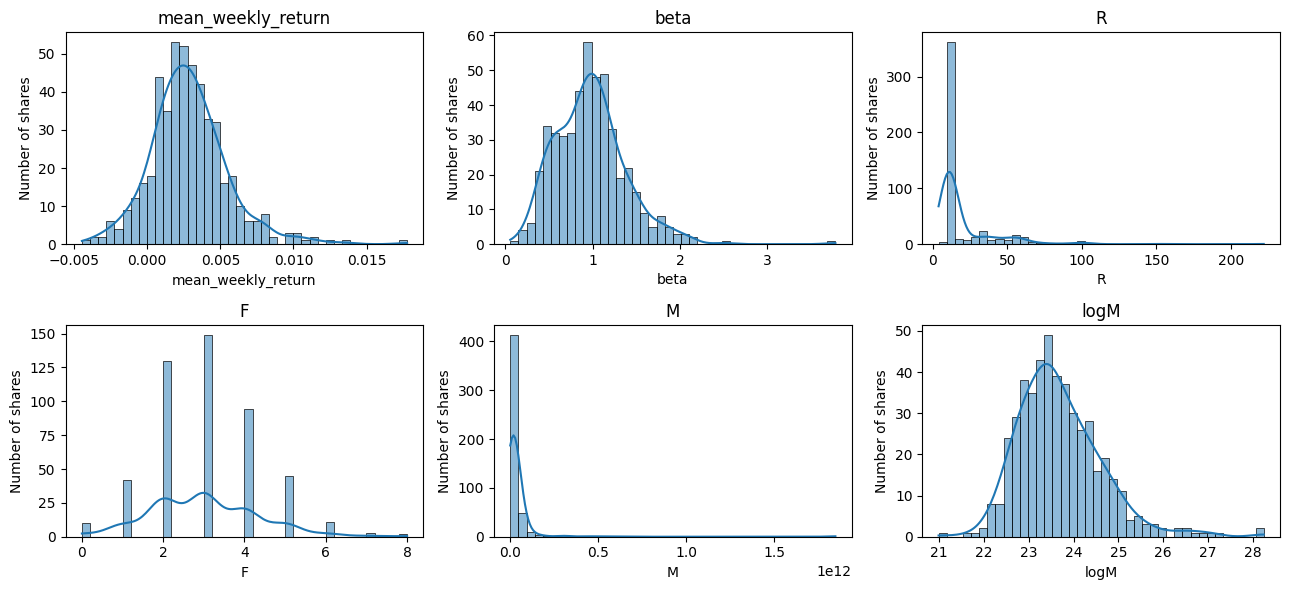

Same shares in both matrices: True | n = 486
Means ~0: [-0.0, 0.0] [-0.0, -0.0, -0.0]
Stds  ~1: [1.0, 1.0] [1.0, 1.0, 1.0]


In [27]:
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler

#Two separate feature matrices for the same eligible shares (valid Recency, Task 1.4)
eligible_features = feature_table.loc[rfm_shares].copy()
risk_return = eligible_features[["mean_weekly_return", "beta"]].copy()
activity = eligible_features[["R", "F", "M"]].copy()
activity["logM"] = np.log1p(activity["M"])          # log1p on M only (spec 2.1)
activity_model = activity[["R", "F", "logM"]]

# Inspect skew and outliers (|z| > 3) before and after the transform
check_cols = pd.concat([risk_return, activity[["R", "F", "M", "logM"]]], axis=1)
z = (check_cols - check_cols.mean()) / check_cols.std()
print(pd.DataFrame({"skew": check_cols.apply(stats.skew),
                    "outliers_|z|>3": (z.abs() > 3).sum()}).round(2))

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), ["mean_weekly_return", "beta", "R", "F", "M", "logM"]):
    sns.histplot(check_cols[col], bins=40, kde=True, ax=ax)
    ax.set_ylabel("Number of shares")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Standardise each matrix separately
X_rr = pd.DataFrame(StandardScaler().fit_transform(risk_return),
                    index=risk_return.index, columns=risk_return.columns)
X_act = pd.DataFrame(StandardScaler().fit_transform(activity_model),
                     index=activity_model.index, columns=activity_model.columns)

print("Same shares in both matrices:", X_rr.index.equals(X_act.index), "| n =", len(X_rr))
print("Means ~0:", X_rr.mean().round(2).tolist(), X_act.mean().round(2).tolist())
print("Stds  ~1:", X_rr.std(ddof=0).round(2).tolist(), X_act.std(ddof=0).round(2).tolist())

2.1 Skew of other variables after log1p

In [28]:
cmp = pd.DataFrame({
    "skew original": eligible_features[["beta", "R", "F"]].apply(stats.skew),
    "skew after log1p": np.log1p(eligible_features[["beta", "R", "F"]]).apply(stats.skew),
})
print(cmp.round(2))

      skew original  skew after log1p
beta           1.10              0.15
R              3.63              1.58
F              0.42             -0.93


Task 2.2 Ward hierarchical clustering

Ward - return and beta
   silhouette  smallest_cluster                             sizes
k                                                                
2       0.339                92                         [394, 92]
3       0.274                92                    [230, 164, 92]
4       0.282                48                [182, 164, 92, 48]
5       0.304                48             [182, 98, 92, 66, 48]
6       0.320                 5          [182, 98, 87, 66, 48, 5]
7       0.324                 5      [160, 98, 87, 66, 48, 22, 5]
8       0.321                 5  [160, 98, 66, 56, 48, 31, 22, 5]

Ward - R, F, logM
   silhouette  smallest_cluster                              sizes
k                                                                 
2       0.368                82                          [404, 82]
3       0.304                82                     [250, 154, 82]
4       0.289                43                 [207, 154, 82, 43]
5       0.305                

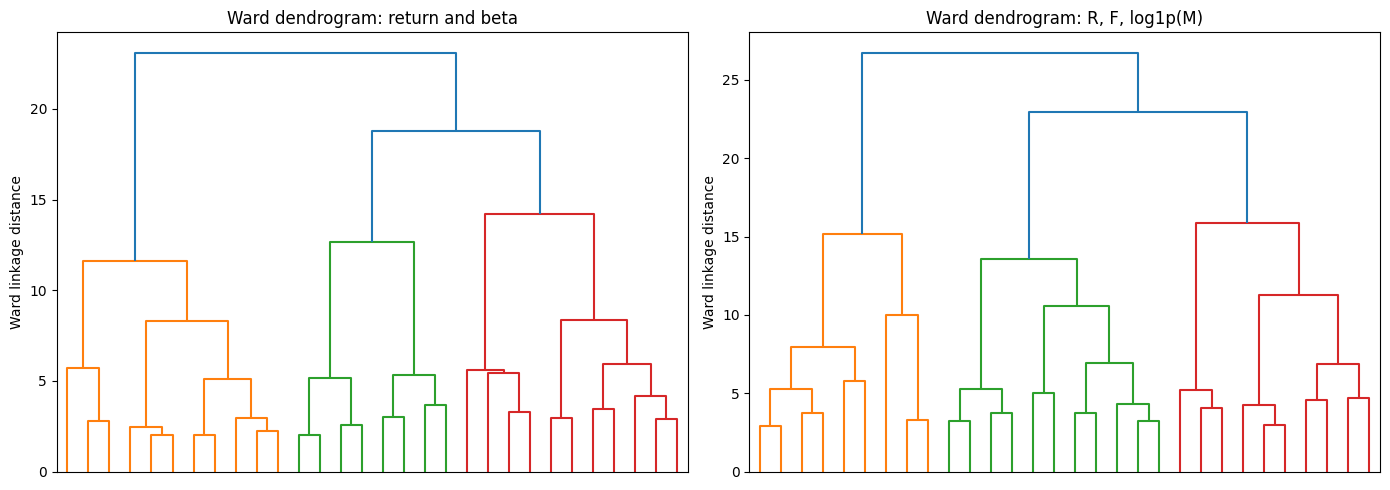

In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score

def ward_table(X):
    tree = linkage(X, method="ward", metric="euclidean")
    rows = []
    for k in range(2, 9):
        labels = cut_tree(tree, n_clusters=k).ravel()
        sizes = np.bincount(labels)
        rows.append({"k": k,
                     "silhouette": silhouette_score(X, labels),
                     "smallest_cluster": int(sizes.min()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return tree, pd.DataFrame(rows).set_index("k")

link_rr, ward_rr_table = ward_table(X_rr)
link_act, ward_act_table = ward_table(X_act)

print("Ward - return and beta")
print(ward_rr_table.round(3))
print()
print("Ward - R, F, logM")
print(ward_act_table.round(3))

# One dendrogram per matrix (truncated to the last 30 merges so it is readable)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tree, title in [(axes[0], link_rr, "Ward dendrogram: return and beta"),
                        (axes[1], link_act, "Ward dendrogram: R, F, log1p(M)")]:
    dendrogram(tree, truncate_mode="lastp", p=30, no_labels=True, ax=ax)
    ax.set_title(title)
    ax.set_ylabel("Ward linkage distance")
plt.tight_layout()
plt.show()

2.2 Ward profiles for k = 2, 3, 4

In [30]:
# Ward profiles (original units) for k = 2, 3 and 4, to support the choice of k
ft = eligible_features.copy()
ft["mean_weekly_return_pct"] = ft["mean_weekly_return"] * 100

def ward_profiles(link, cols, ks=(2, 3, 4)):
    for k in ks:
        lab = cut_tree(link, n_clusters=k).ravel() + 1
        g = ft.assign(cluster=lab).groupby("cluster")
        out = g[cols].mean().round(3)
        out["n_shares"] = g.size()
        print(f"k = {k}")
        print(out)
        print()

print("=== Ward: return and beta ===")
ward_profiles(link_rr, ["mean_weekly_return_pct", "beta"])
print("=== Ward: R, F, M ===")
ward_profiles(link_act, ["R", "F", "M"])

=== Ward: return and beta ===
k = 2
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.205  0.898       394
2                         0.632  1.298        92

k = 3
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.146  1.110       230
2                         0.632  1.298        92
3                         0.287  0.601       164

k = 4
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.132  0.973       182
2                         0.632  1.298        92
3                         0.287  0.601       164
4                         0.200  1.628        48

=== Ward: R, F, M ===
k = 2
              R      F             M  n_shares
cluster                                       
1        12.715  3.171  3.783020e+10       404
2        58.305  2.098  4.715898e+10        8

Task 2.3 K-means clustering

K-means - return and beta
   inertia  silhouette  smallest_cluster                             sizes
k                                                                         
2  621.634       0.387               143                        [343, 143]
3  461.179       0.329               119                   [202, 165, 119]
4  371.571       0.326                41               [160, 153, 132, 41]
5  309.960       0.338                28           [165, 124, 114, 55, 28]
6  265.707       0.326                20        [134, 115, 85, 76, 56, 20]
7  227.239       0.329                 5     [126, 105, 84, 78, 47, 41, 5]
8  194.249       0.354                 5  [135, 80, 78, 76, 43, 40, 29, 5]

K-means - R, F, logM
    inertia  silhouette  smallest_cluster                              sizes
k                                                                           
2  1066.832       0.423                68                          [418, 68]
3   796.614       0.325                64     

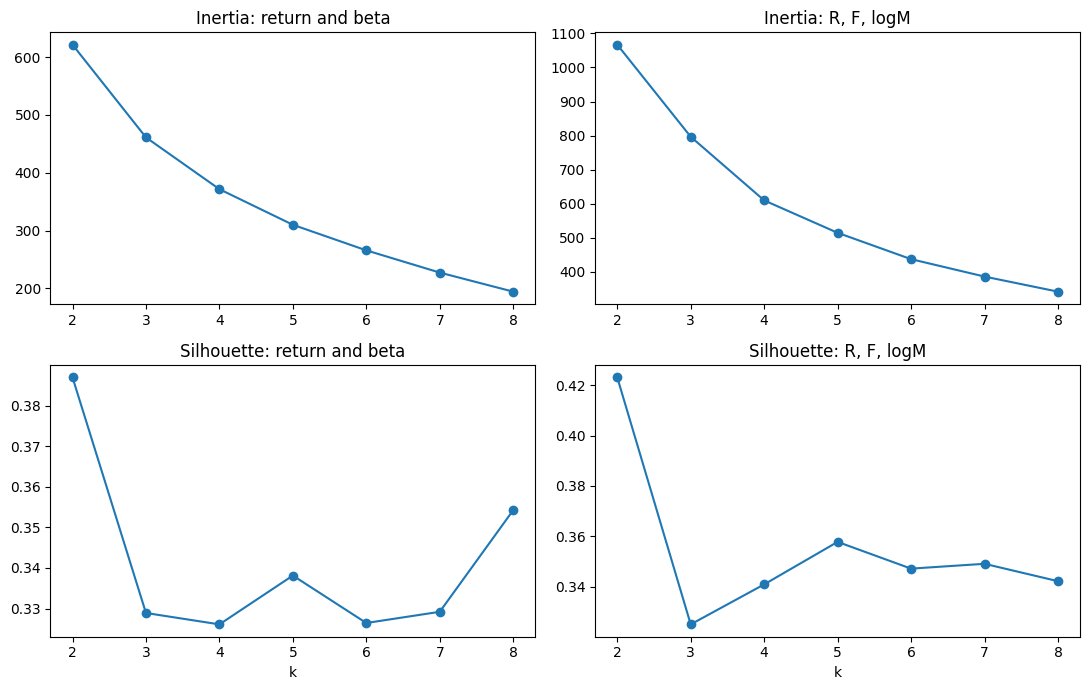

In [31]:
from sklearn.cluster import KMeans

SEED = 42
N_INIT = 50

def kmeans_table(X):
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit(X)
        sizes = np.bincount(km.labels_)
        rows.append({"k": k,
                     "inertia": km.inertia_,
                     "silhouette": silhouette_score(X, km.labels_),
                     "smallest_cluster": int(sizes.min()),
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k")

km_rr_table = kmeans_table(X_rr)
km_act_table = kmeans_table(X_act)

print("K-means - return and beta")
print(km_rr_table.round(3))
print()
print("K-means - R, F, logM")
print(km_act_table.round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (tab, name) in enumerate([(km_rr_table, "return and beta"), (km_act_table, "R, F, logM")]):
    axes[0, j].plot(tab.index, tab["inertia"], marker="o")
    axes[0, j].set_title(f"Inertia: {name}")
    axes[1, j].plot(tab.index, tab["silhouette"], marker="o")
    axes[1, j].set_title(f"Silhouette: {name}")
    axes[1, j].set_xlabel("k")
plt.tight_layout()
plt.show()

Task 2.3 Chosen k for each solution

In [32]:
# Chosen k after reading the Ward and K-means tables (silhouette, cluster sizes, dendrograms)
K_WARD_RR = 3
K_WARD_ACT = 3
K_KM_RR = 3
K_KM_ACT = 3

labels = pd.DataFrame(index=X_rr.index)
labels["ward_rr"] = cut_tree(link_rr, n_clusters=K_WARD_RR).ravel() + 1
labels["ward_act"] = cut_tree(link_act, n_clusters=K_WARD_ACT).ravel() + 1
labels["km_rr"] = KMeans(n_clusters=K_KM_RR, random_state=SEED, n_init=N_INIT).fit_predict(X_rr) + 1
labels["km_act"] = KMeans(n_clusters=K_KM_ACT, random_state=SEED, n_init=N_INIT).fit_predict(X_act) + 1

results = eligible_features.join(labels)
results["mean_weekly_return_pct"] = results["mean_weekly_return"] * 100

for col in labels.columns:
    print(col, "cluster sizes:", results[col].value_counts().sort_index().tolist())

ward_rr cluster sizes: [230, 92, 164]
ward_act cluster sizes: [250, 154, 82]
km_rr cluster sizes: [119, 202, 165]
km_act cluster sizes: [270, 64, 152]


2.3 K-means stability across seeds

In [33]:
from sklearn.metrics import adjusted_rand_score

# K-means stability: different seeds, and why multiple initialisations are used
rows = []
for name, X, col, k in [("return and beta", X_rr, "km_rr", K_KM_RR), ("R, F, logM", X_act, "km_act", K_KM_ACT)]:
    ari = []
    for s in range(10):
        lab = KMeans(n_clusters=k, random_state=s, n_init=N_INIT).fit_predict(X)
        ari.append(adjusted_rand_score(results[col], lab))
    single = [KMeans(n_clusters=k, random_state=s, n_init=1).fit(X).inertia_ for s in range(10)]
    multi = [KMeans(n_clusters=k, random_state=s, n_init=N_INIT).fit(X).inertia_ for s in range(10)]
    rows.append({"matrix": name, "k": k,
                 "min ARI vs chosen solution (10 seeds)": min(ari),
                 "inertia range, n_init=1": f"{min(single):.1f} to {max(single):.1f}",
                 f"inertia range, n_init={N_INIT}": f"{min(multi):.1f} to {max(multi):.1f}"})
print(pd.DataFrame(rows).set_index("matrix").round(3).to_string())

                 k  min ARI vs chosen solution (10 seeds) inertia range, n_init=1 inertia range, n_init=50
matrix                                                                                                    
return and beta  3                                  1.000          461.2 to 461.2           461.2 to 461.2
R, F, logM       3                                  0.993          796.6 to 915.3           796.6 to 796.6


2.3 Comparison of k = 3 and k = 4 (return and beta)

In [34]:
# Compare k = 3 and k = 4 for the return and beta solutions (evidence for the choice of k)
for k in (3, 4):
    w = cut_tree(link_rr, n_clusters=k).ravel() + 1
    km = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit_predict(X_rr) + 1
    print(f"===== k = {k} | ARI Ward vs K-means: {adjusted_rand_score(w, km):.3f} | "
          f"silhouette Ward {silhouette_score(X_rr, w):.3f}, K-means {silhouette_score(X_rr, km):.3f}")
    for name, lab in [("Ward", w), ("K-means", km)]:
        g = ft.assign(cluster=lab).groupby("cluster")
        out = g[["mean_weekly_return_pct", "beta"]].mean().round(3)
        out["n_shares"] = g.size()
        print(name); print(out); print()

===== k = 3 | ARI Ward vs K-means: 0.516 | silhouette Ward 0.274, K-means 0.329
Ward
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.146  1.110       230
2                         0.632  1.298        92
3                         0.287  0.601       164

K-means
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.596  1.326       119
2                         0.259  0.631       202
3                         0.095  1.139       165

===== k = 4 | ARI Ward vs K-means: 0.265 | silhouette Ward 0.282, K-means 0.326
Ward
         mean_weekly_return_pct   beta  n_shares
cluster                                         
1                         0.132  0.973       182
2                         0.632  1.298        92
3                         0.287  0.601       164
4                         0.200  1.628        48

K-means
         mean_weekly_return

Task 2.4 Cluster profiles in original units

In [35]:
def profile(col, cols):
    g = results.groupby(col)[cols]
    out = g.mean().add_suffix("_mean").join(g.median().add_suffix("_median"))
    out["n_shares"] = results.groupby(col).size()
    return out
pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
for col, cols in [("ward_rr", ["mean_weekly_return_pct", "beta"]),
                  ("km_rr", ["mean_weekly_return_pct", "beta"]),
                  ("ward_act", ["R", "F", "M"]),
                  ("km_act", ["R", "F", "M"])]:
    print(f"--- Profile: {col} (original units) ---")
    print(profile(col, cols).round(3))
    print()

--- Profile: ward_rr (original units) ---
         mean_weekly_return_pct_mean  beta_mean  mean_weekly_return_pct_median  beta_median  n_shares
ward_rr                                                                                              
1                              0.146      1.110                          0.171        1.038       230
2                              0.632      1.298                          0.550        1.218        92
3                              0.287      0.601                          0.327        0.578       164

--- Profile: km_rr (original units) ---
       mean_weekly_return_pct_mean  beta_mean  mean_weekly_return_pct_median  beta_median  n_shares
km_rr                                                                                              
1                            0.596      1.326                          0.528        1.221       119
2                            0.259      0.631                          0.259        0.622       202
3      

2.4 Cluster profiles chart (original units)

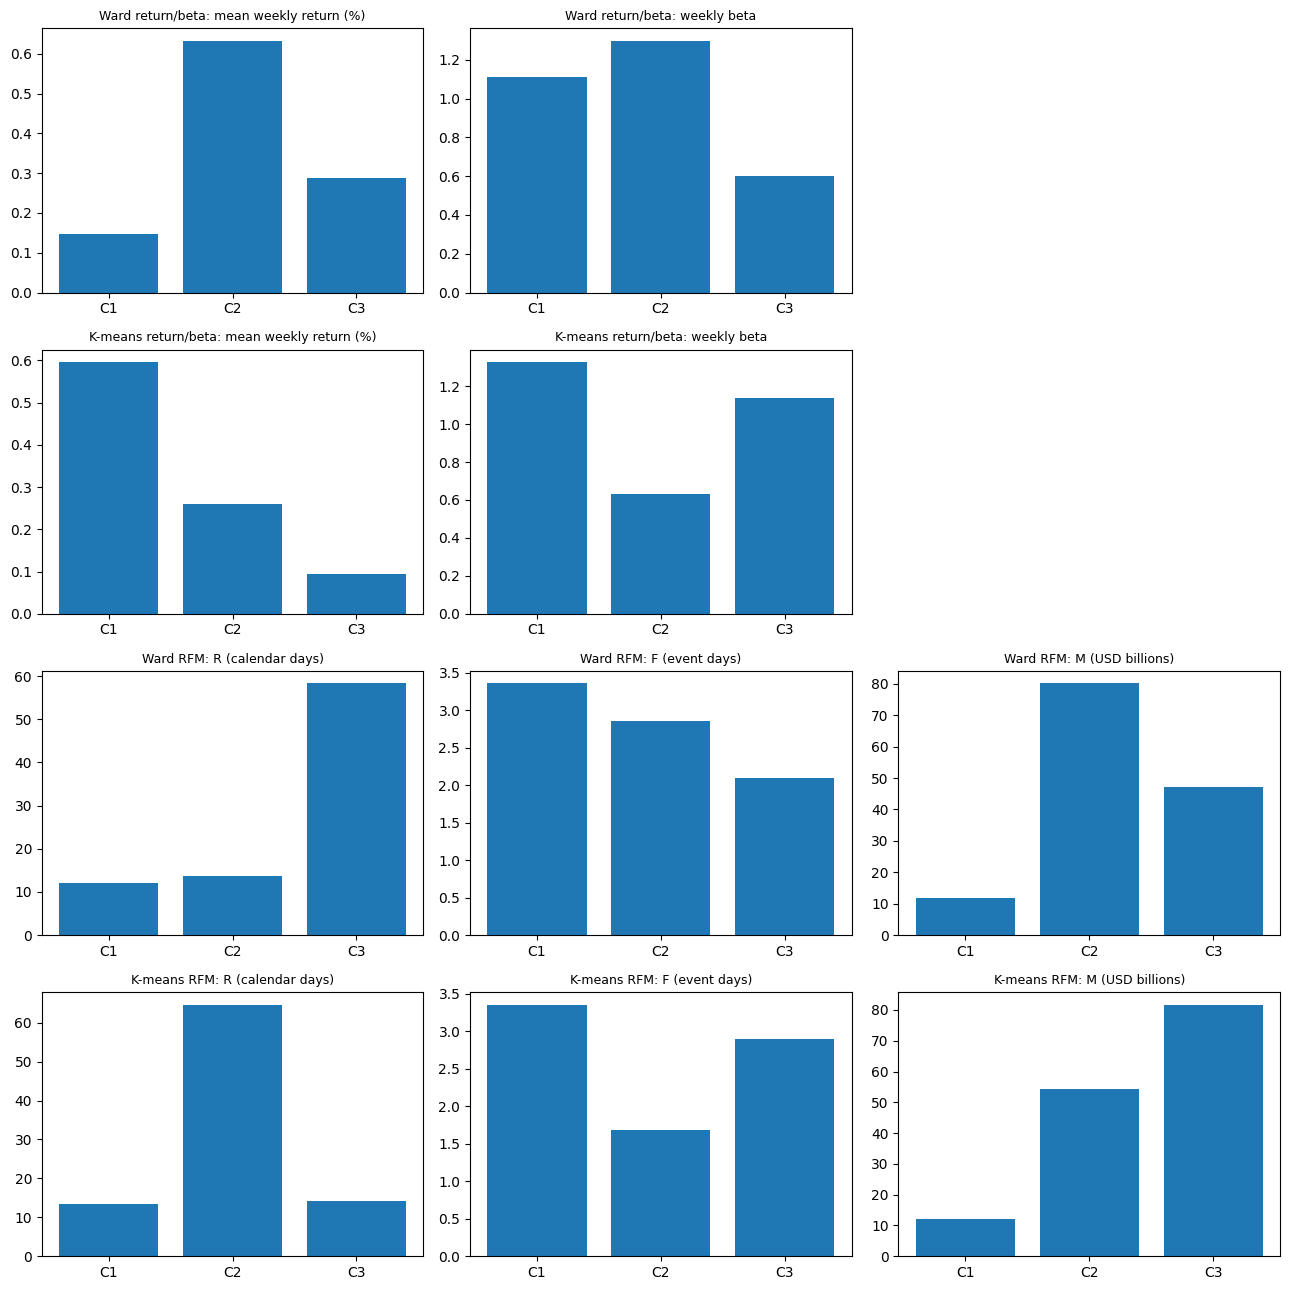

In [36]:
# Cluster profiles in original units (mean of each feature per cluster)
spec = [("ward_rr", ["mean_weekly_return_pct", "beta"], "Ward return/beta"),
        ("km_rr", ["mean_weekly_return_pct", "beta"], "K-means return/beta"),
        ("ward_act", ["R", "F", "M"], "Ward RFM"),
        ("km_act", ["R", "F", "M"], "K-means RFM")]
names = {"mean_weekly_return_pct": "mean weekly return (%)", "beta": "weekly beta",
         "R": "R (calendar days)", "F": "F (event days)", "M": "M (USD billions)"}

fig, axes = plt.subplots(4, 3, figsize=(13, 13))
for r, (col, feats, title) in enumerate(spec):
    g = results.groupby(col)
    for c in range(3):
        ax = axes[r, c]
        if c >= len(feats):
            ax.axis("off")
            continue
        vals = g[feats[c]].mean()
        if feats[c] == "M":
            vals = vals / 1e9
        ax.bar([f"C{i}" for i in vals.index], vals.values)
        ax.set_title(f"{title}: {names[feats[c]]}", fontsize=9)
plt.tight_layout()
plt.show()

Task 2.4 Labelled 2D views

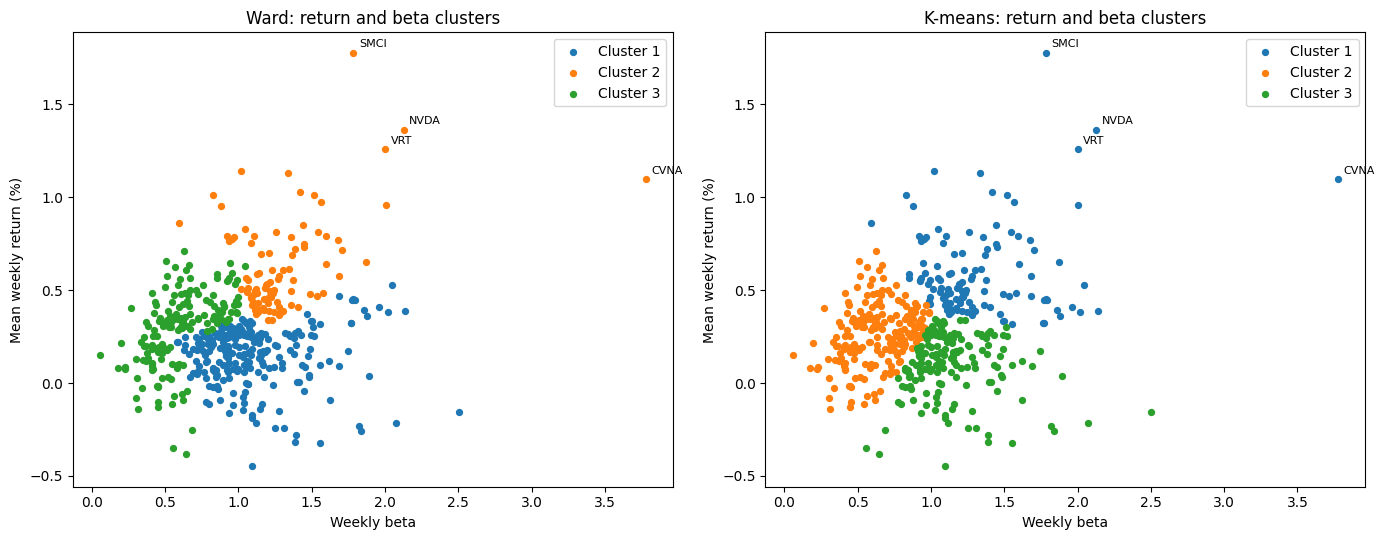

PCA explained variance: [0.458 0.336]
        PC1    PC2
R     0.711  0.023
F    -0.650  0.402
logM  0.268  0.915


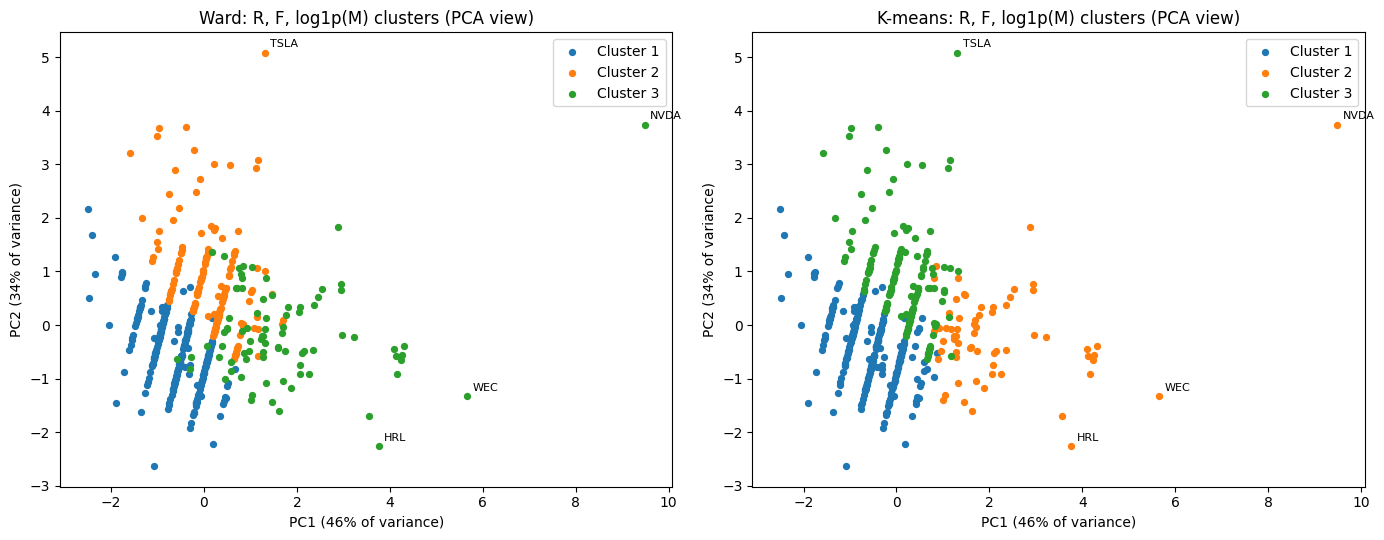

In [37]:
from sklearn.decomposition import PCA

def annotate(ax, x, y, names, n=4):
    # label the shares that sit furthest from the centre of the plot
    d = ((x - x.mean()) / x.std()) ** 2 + ((y - y.mean()) / y.std()) ** 2
    for t in d.nlargest(n).index:
        ax.annotate(t, (x[t], y[t]), fontsize=8, xytext=(4, 4), textcoords="offset points")

# Return and beta: 2 features, so plotted directly in original units
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, title in [(axes[0], "ward_rr", "Ward"), (axes[1], "km_rr", "K-means")]:
    for c, grp in results.groupby(col):
        ax.scatter(grp["beta"], grp["mean_weekly_return_pct"], s=18, label=f"Cluster {c}")
    annotate(ax, results["beta"], results["mean_weekly_return_pct"], results.index)
    ax.set_xlabel("Weekly beta")
    ax.set_ylabel("Mean weekly return (%)")
    ax.set_title(f"{title}: return and beta clusters")
    ax.legend()
plt.tight_layout()
plt.show()

# R, F, logM: 3 features, so PCA reduces the standardised matrix to 2 components for plotting only
pca = PCA(n_components=2, random_state=SEED).fit(X_act)
P = pd.DataFrame(pca.transform(X_act), index=X_act.index, columns=["PC1", "PC2"])
print("PCA explained variance:", pca.explained_variance_ratio_.round(3))
print(pd.DataFrame(pca.components_.T, index=X_act.columns, columns=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, title in [(axes[0], "ward_act", "Ward"), (axes[1], "km_act", "K-means")]:
    for c in sorted(results[col].unique()):
        idx = results.index[results[col] == c]
        ax.scatter(P.loc[idx, "PC1"], P.loc[idx, "PC2"], s=18, label=f"Cluster {c}")
    annotate(ax, P["PC1"], P["PC2"], P.index)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    ax.set_title(f"{title}: R, F, log1p(M) clusters (PCA view)")
    ax.legend()
plt.tight_layout()
plt.show()

Task 2.4 Ward vs K-means comparison

In [38]:
from sklearn.metrics import adjusted_rand_score

comparison = pd.DataFrame({
    "ARI (Ward vs K-means)": [adjusted_rand_score(results["ward_rr"], results["km_rr"]),
                              adjusted_rand_score(results["ward_act"], results["km_act"])],
    "silhouette Ward": [silhouette_score(X_rr, results["ward_rr"]),
                        silhouette_score(X_act, results["ward_act"])],
    "silhouette K-means": [silhouette_score(X_rr, results["km_rr"]),
                           silhouette_score(X_act, results["km_act"])],
}, index=["return and beta", "R, F, logM"])
print(comparison.round(3))
print()
print(pd.crosstab(results["ward_rr"], results["km_rr"], rownames=["Ward"], colnames=["K-means"]))
print()
print(pd.crosstab(results["ward_act"], results["km_act"], rownames=["Ward"], colnames=["K-means"]))

                 ARI (Ward vs K-means)  silhouette Ward  silhouette K-means
return and beta                  0.516            0.274               0.329
R, F, logM                       0.834            0.304               0.325

K-means   1    2    3
Ward                 
1        16   54  160
2        90    0    2
3        13  148    3

K-means    1   2    3
Ward                 
1        250   0    0
2          5   5  144
3         15  59    8


Task 2.5.1 Correlation of R, F and log M

          R      F   logM
R     1.000 -0.346  0.152
F    -0.346  1.000  0.013
logM  0.152  0.013  1.000


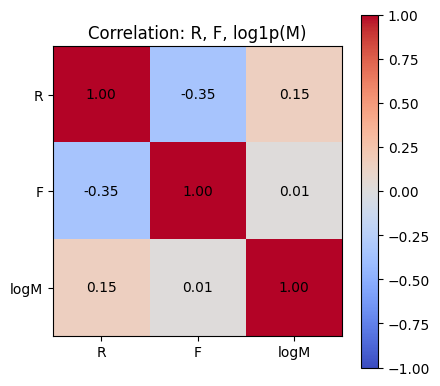

In [39]:
corr = activity_model.corr()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(3)); ax.set_yticklabels(corr.columns)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Correlation: R, F, log1p(M)")
plt.colorbar(im)
plt.tight_layout()
plt.show()

2.5.1 Shared variance among R, F and log M

In [40]:
# Shared variance among the standardised R, F and log1p(M)
eig = np.sort(np.linalg.eigvalsh(corr.values))[::-1]
print("Eigenvalues of the correlation matrix:", eig.round(3))
print("Share of total variance:", (eig / eig.sum()).round(3), "(equal weights would be 0.333 each)")
corr.round(3).to_csv("outputs/rfm_correlation.csv")

Eigenvalues of the correlation matrix: [1.374 1.009 0.617]
Share of total variance: [0.458 0.336 0.206] (equal weights would be 0.333 each)


Task 2.5.2 Ward on R and F only

Adjusted Rand index, Ward R,F,logM vs Ward R,F only (k = 3): 0.291

R,F only   1    2   3
R,F,logM             
1         66  183   1
2         59   86   9
3          0    3  79

Full RFM clusters (R, F, logM):
          n_shares  R_mean  F_mean      M_median        M_mean
ward_act                                                      
1              250    12.1     3.4  1.117761e+10  1.176413e+10
2              154    13.7     2.9  3.969545e+10  8.014525e+10
3               82    58.3     2.1  1.784903e+10  4.715898e+10

R,F-only clusters:
              n_shares  R_mean  F_mean      M_median        M_mean
ward_rf_only                                                      
1                  125    11.0     1.8  1.769899e+10  3.433790e+10
2                  272    12.9     3.9  1.485534e+10  3.940097e+10
3                   89    56.6     2.0  2.084781e+10  4.652963e+10


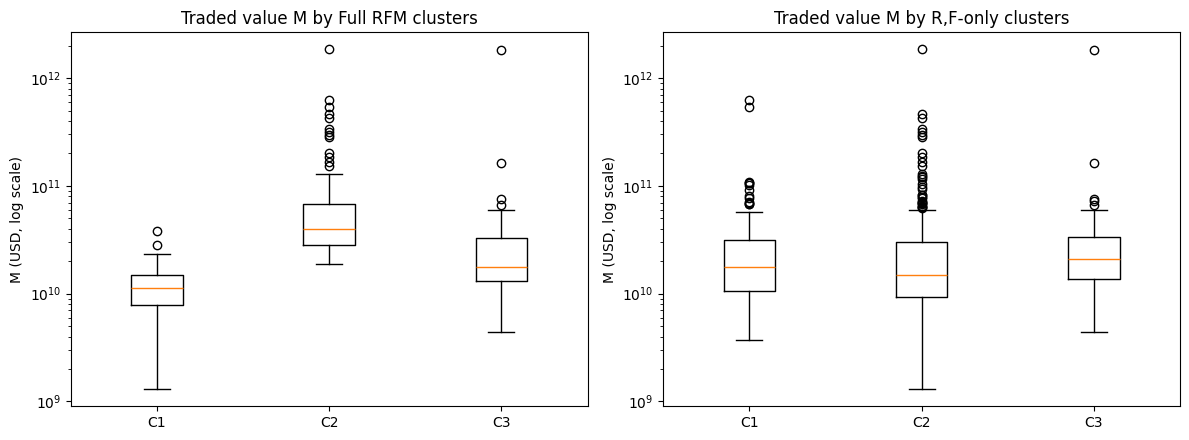

In [41]:
# Ward on R and F only: same shares, same k, standardised afresh
X_rf = StandardScaler().fit_transform(activity_model[["R", "F"]])
link_rf = linkage(X_rf, method="ward", metric="euclidean")
results["ward_rf_only"] = cut_tree(link_rf, n_clusters=K_WARD_ACT).ravel() + 1

print(f"Adjusted Rand index, Ward R,F,logM vs Ward R,F only (k = {K_WARD_ACT}):",
      round(adjusted_rand_score(results["ward_act"], results["ward_rf_only"]), 3))
print()
print(pd.crosstab(results["ward_act"], results["ward_rf_only"],
                  rownames=["R,F,logM"], colnames=["R,F only"]))

# Traded value (M, USD) profile of each solution
def m_profile(col):
    g = results.groupby(col)
    return pd.DataFrame({"n_shares": g.size(), "R_mean": g["R"].mean(), "F_mean": g["F"].mean(),
                         "M_median": g["M"].median(), "M_mean": g["M"].mean()})

print()
print("Full RFM clusters (R, F, logM):")
print(m_profile("ward_act").round(1))
print()
print("R,F-only clusters:")
print(m_profile("ward_rf_only").round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, title in [(axes[0], "ward_act", "Full RFM clusters"), (axes[1], "ward_rf_only", "R,F-only clusters")]:
    groups = sorted(results[col].unique())
    ax.boxplot([results.loc[results[col] == g, "M"] for g in groups])
    ax.set_xticklabels([f"C{g}" for g in groups])
    ax.set_yscale("log")
    ax.set_title(f"Traded value M by {title}")
    ax.set_ylabel("M (USD, log scale)")
plt.tight_layout()
plt.show()

3.1 Data mart evidence

In [42]:
# Data mart evidence: build the proposed tables from the notebook's own data and save them
os.makedirs("outputs/data_mart", exist_ok=True)

def long(df, name):
    out = df.copy()
    out.index.name = "Date"
    out.columns.name = "Ticker"
    return out.reset_index().melt(id_vars="Date", var_name="Ticker", value_name=name)

fact_daily = (long(adj_v, "adj_close")
              .merge(long(close_v, "close"), on=["Date", "Ticker"])
              .merge(long(vol_v, "volume"), on=["Date", "Ticker"])
              .merge(long(baseline[valid], "baseline_20d"), on=["Date", "Ticker"])
              .merge(long(high_vol[valid].astype(int), "high_volume_flag"), on=["Date", "Ticker"]))
fact_daily["traded_value"] = fact_daily["close"] * fact_daily["volume"]

dim_share = feature_table[["Security", "GICS Sector"]].reset_index()

fact_share_features = results.reset_index().rename(columns={
    "ward_rr": "cluster_ward_return_beta", "km_rr": "cluster_kmeans_return_beta",
    "ward_act": "cluster_ward_rfm", "km_act": "cluster_kmeans_rfm"})
fact_share_features["observation_date"] = str(obs_date.date())
fact_share_features["calculation_version"] = "cwk1-v1.0"
fact_share_features["random_seed"] = SEED

fact_daily.to_csv("outputs/data_mart/fact_daily.csv.gz", index=False)
dim_share.to_csv("outputs/data_mart/dim_share.csv", index=False)
fact_share_features.to_csv("outputs/data_mart/fact_share_features.csv", index=False)

schema = pd.DataFrame([
    ["fact_daily", "one share on one trading day", len(fact_daily), "Date, Ticker"],
    ["fact_share_features", "one share (RFM, return, beta, cluster labels, version)", len(fact_share_features), "Ticker"],
    ["dim_share", "one share (name, GICS sector)", len(dim_share), "Ticker"],
], columns=["table", "grain", "rows", "keys"])
print(schema.to_string(index=False))
print()
print("fact_daily columns:", list(fact_daily.columns))
print("fact_share_features columns:", list(fact_share_features.columns))

              table                                                  grain   rows         keys
         fact_daily                           one share on one trading day 488430 Date, Ticker
fact_share_features one share (RFM, return, beta, cluster labels, version)    486       Ticker
          dim_share                          one share (name, GICS sector)    486       Ticker

fact_daily columns: ['Date', 'Ticker', 'adj_close', 'close', 'volume', 'baseline_20d', 'high_volume_flag', 'traded_value']
fact_share_features columns: ['Ticker', 'mean_weekly_return', 'beta', 'R', 'F', 'M', 'Security', 'GICS Sector', 'cluster_ward_return_beta', 'cluster_ward_rfm', 'cluster_kmeans_return_beta', 'cluster_kmeans_rfm', 'mean_weekly_return_pct', 'ward_rf_only', 'observation_date', 'calculation_version', 'random_seed']


3.1 Data mart: date, sector and benchmark dimensions and weekly fact table

In [43]:
# Calendar dates (weekends and holidays included) so Friday week labels always join
dim_date = pd.DataFrame({"Date": pd.date_range(start=adj_v.index.min(), end=adj_v.index.max(), freq="D")})
dim_date["is_trading_day"] = dim_date["Date"].isin(adj_v.index)
dim_date["week_ending_friday"] = dim_date["Date"].dt.to_period("W-FRI").dt.end_time.dt.normalize()
dim_date["year"] = dim_date["Date"].dt.year
dim_date["in_60_session_window"] = dim_date["Date"].isin(last60)
dim_date["is_observation_date"] = dim_date["Date"] == obs_date

dim_sector = (feature_table["GICS Sector"].drop_duplicates().sort_values()
              .reset_index(drop=True).rename_axis("sector_id").reset_index())

dim_benchmark = pd.DataFrame({"benchmark_id": ["^GSPC"], "name": ["S&P 500 index"],
                              "price_basis": ["Adj Close (price index, no dividends)"]})
fact_benchmark_daily = index_adj.iloc[:, 0].rename("adj_close").rename_axis("Date").reset_index()
fact_benchmark_daily["benchmark_id"] = "^GSPC"

fact_weekly = weekly_ret.stack().rename("weekly_return").rename_axis(["week_ending", "Ticker"]).reset_index()
fact_weekly = fact_weekly.merge(market_ret.rename("benchmark_return").rename_axis("week_ending").reset_index(),
                                on="week_ending")
assert fact_weekly["week_ending"].isin(dim_date["Date"]).all(), "Some weekly dates are missing from dim_date"

for name, df in [("dim_date", dim_date), ("dim_sector", dim_sector), ("dim_benchmark", dim_benchmark),
                 ("fact_benchmark_daily", fact_benchmark_daily), ("fact_weekly", fact_weekly)]:
    df.to_csv(f"outputs/data_mart/{name}.csv", index=False)
    print(f"{name}: {len(df)} rows, columns {list(df.columns)}")

dim_date: 1458 rows, columns ['Date', 'is_trading_day', 'week_ending_friday', 'year', 'in_60_session_window', 'is_observation_date']
dim_sector: 11 rows, columns ['sector_id', 'GICS Sector']
dim_benchmark: 1 rows, columns ['benchmark_id', 'name', 'price_basis']
fact_benchmark_daily: 1005 rows, columns ['Date', 'adj_close', 'benchmark_id']
fact_weekly: 100602 rows, columns ['week_ending', 'Ticker', 'weekly_return', 'benchmark_return']


3.2.1 Cluster profiles and sector composition

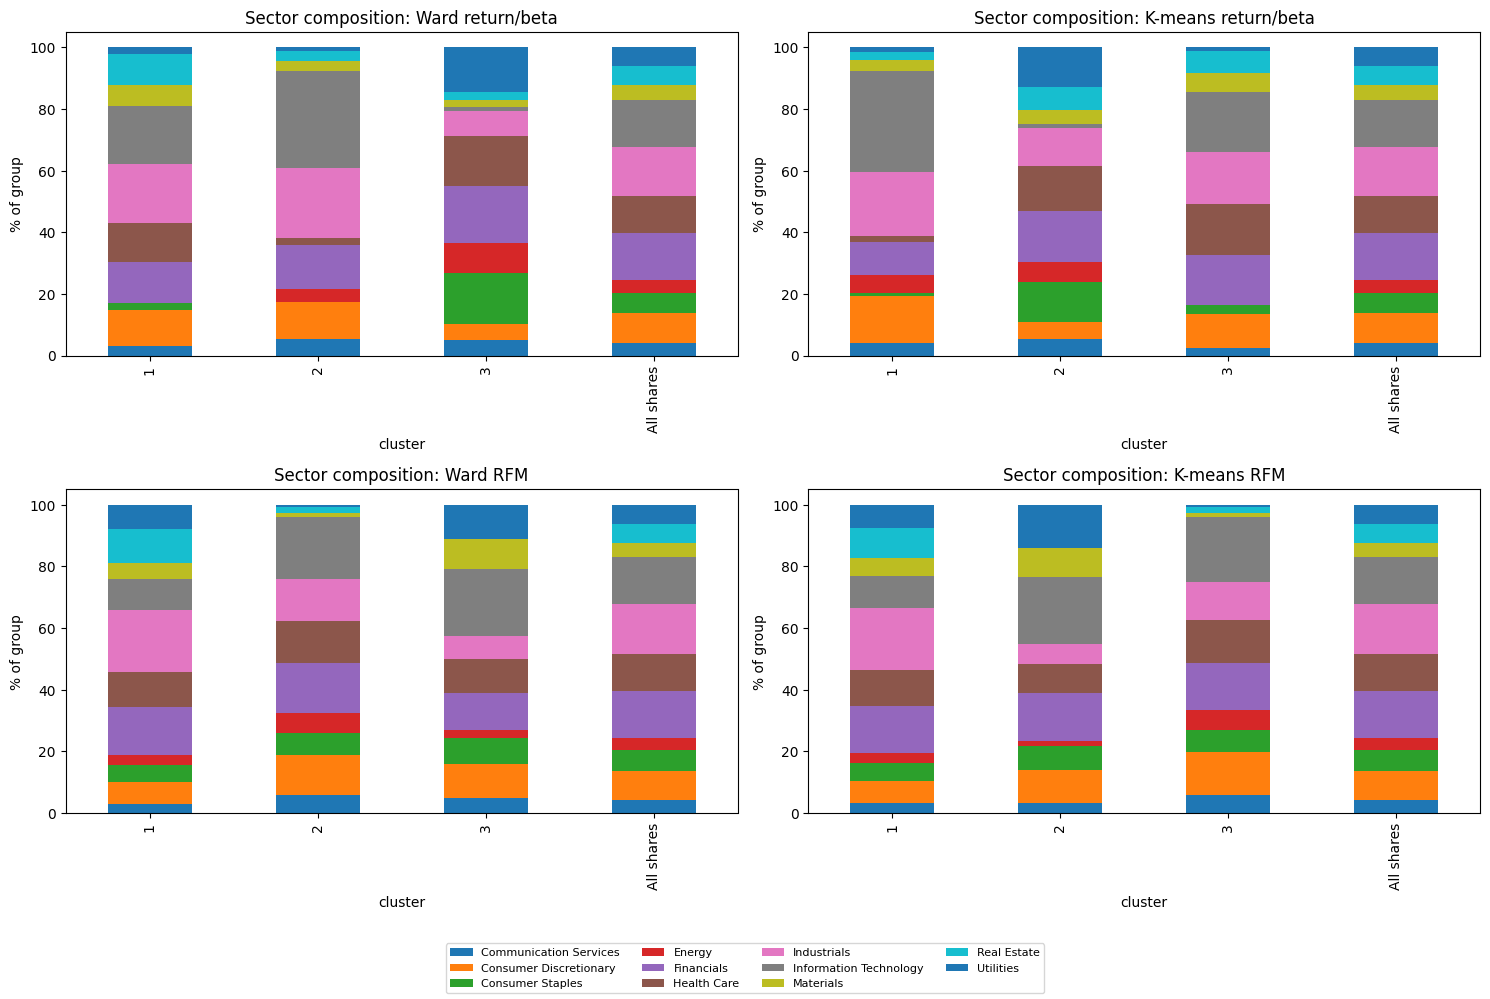

Sector composition tables saved in outputs/ (one csv per solution)


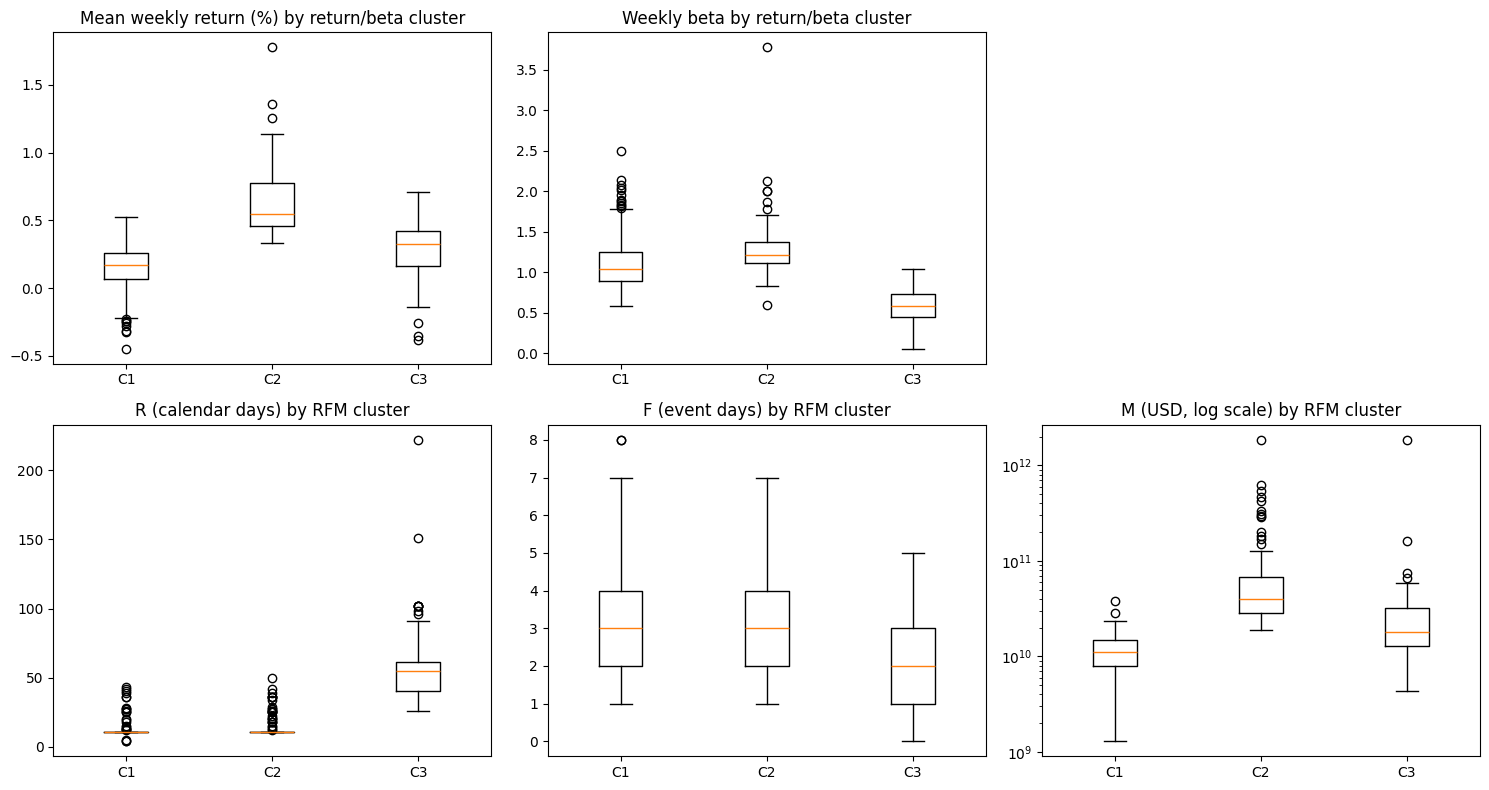

Shares in each return/beta x RFM cluster pair:
RFM cluster            1   2   3
return/beta cluster             
1                    134  59  37
2                     36  37  19
3                     80  58  26
ARI between the two groupings: 0.024

Mean return (%) and beta by RFM cluster:
          mean_weekly_return_pct   beta
ward_act                               
1                          0.253  0.940
2                          0.338  1.010
3                          0.286  1.009

Median R, F, M by return/beta cluster:
            R    F             M
ward_rr                         
1        11.0  3.0  1.411142e+10
2        11.0  3.0  2.418413e+10
3        11.0  3.0  1.764940e+10


In [44]:
os.makedirs("outputs/figures", exist_ok=True)
sector_col = "GICS Sector"
sol = {"ward_rr": "Ward return/beta", "km_rr": "K-means return/beta",
       "ward_act": "Ward RFM", "km_act": "K-means RFM"}

# (a) Sector composition of every cluster (% of the cluster), with all shares as a reference bar
overall = results[sector_col].value_counts(normalize=True).mul(100)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, title) in zip(axes.ravel(), sol.items()):
    comp = pd.crosstab(results[col], results[sector_col], normalize="index") * 100
    comp.to_csv(f"outputs/sector_composition_{col}.csv")
    plot_df = pd.concat([comp, overall.rename("All shares").to_frame().T])
    plot_df.plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(f"Sector composition: {title}")
    ax.set_ylabel("% of group")
    ax.set_xlabel("cluster")
handles, names = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=4, fontsize=8)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig("outputs/figures/3_2_1_sector_composition.png", dpi=200, bbox_inches="tight")
plt.show()
print("Sector composition tables saved in outputs/ (one csv per solution)")

# (b) Original-unit profiles side by side (Ward solutions)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, v, lab in [(axes[0, 0], "mean_weekly_return_pct", "Mean weekly return (%)"), (axes[0, 1], "beta", "Weekly beta")]:
    groups = sorted(results["ward_rr"].unique())
    ax.boxplot([results.loc[results["ward_rr"] == g, v] for g in groups])
    ax.set_xticklabels([f"C{g}" for g in groups]); ax.set_title(f"{lab} by return/beta cluster")
axes[0, 2].axis("off")
for ax, v, lab in [(axes[1, 0], "R", "R (calendar days)"), (axes[1, 1], "F", "F (event days)"), (axes[1, 2], "M", "M (USD, log scale)")]:
    groups = sorted(results["ward_act"].unique())
    ax.boxplot([results.loc[results["ward_act"] == g, v] for g in groups])
    ax.set_xticklabels([f"C{g}" for g in groups]); ax.set_title(f"{lab} by RFM cluster")
    if v == "M":
        ax.set_yscale("log")
plt.tight_layout()
plt.savefig("outputs/figures/3_2_1_original_unit_profiles.png", dpi=200, bbox_inches="tight")
plt.show()

# (c) How the two kinds of cluster relate (Ward solutions)
ct = pd.crosstab(results["ward_rr"], results["ward_act"], rownames=["return/beta cluster"], colnames=["RFM cluster"])
print("Shares in each return/beta x RFM cluster pair:")
print(ct)
print("ARI between the two groupings:", round(adjusted_rand_score(results["ward_rr"], results["ward_act"]), 3))
print()
print("Mean return (%) and beta by RFM cluster:")
print(results.groupby("ward_act")[["mean_weekly_return_pct", "beta"]].mean().round(3))
print()
print("Median R, F, M by return/beta cluster:")
print(results.groupby("ward_rr")[["R", "F", "M"]].median().round(1))

3.2.2 Monitoring example

In [45]:
# Monitoring example: shares in the Ward RFM cluster with the highest median traded value
top = results.groupby("ward_act")["M"].median().idxmax()
watch = results[results["ward_act"] == top].sort_values(["F", "M"], ascending=False).head(10)
watch = watch[["Security", "GICS Sector", "R", "F", "M"]].copy()
watch["M (USD bn)"] = (watch["M"] / 1e9).round(1)
print(f"Ward RFM cluster {top}: highest median traded value ({len(results[results['ward_act'] == top])} shares)")
print(watch.drop(columns="M").to_string())

Ward RFM cluster 2: highest median traded value (154 shares)
                       Security             GICS Sector   R  F  M (USD bn)
Ticker                                                                    
UNH          UnitedHealth Group             Health Care  14  7       151.3
AVGO                   Broadcom  Information Technology  11  6       334.0
PLTR      Palantir Technologies  Information Technology  11  6       286.9
HON      Honeywell Technologies             Industrials  15  6        59.1
TSLA                Tesla, Inc.  Consumer Discretionary  50  5      1847.7
AMZN                     Amazon  Consumer Discretionary  11  5       468.2
GOOGL   Alphabet Inc. (Class A)  Communication Services  20  5       294.4
GOOG    Alphabet Inc. (Class C)  Communication Services  11  5       202.8
SMCI                 Supermicro  Information Technology  29  5       167.7
BA                       Boeing             Industrials  11  5       127.7


3.2.3 Return dependence and adjustment evidence

In [46]:
# Return dependence: do shares in the same cluster move together?
tick = results.index
corr_w = weekly_ret[tick].corr().values
n = len(tick)
off = ~np.eye(n, dtype=bool)

def within_between(lab):
    same = (lab[:, None] == lab[None, :]) & off
    diff = lab[:, None] != lab[None, :]
    return corr_w[same].mean(), corr_w[diff].mean()

rows = []
for col, title in [("ward_rr", "Ward return/beta"), ("km_rr", "K-means return/beta"),
                   ("ward_act", "Ward RFM"), ("km_act", "K-means RFM"),
                   ("GICS Sector", "GICS sector (reference)")]:
    w, b = within_between(results[col].to_numpy())
    rows.append({"grouping": title, "mean corr within groups": w, "mean corr between groups": b})
print(pd.DataFrame(rows).set_index("grouping").round(3).to_string())

rng = np.random.default_rng(SEED)
rand = [within_between(rng.permutation(results["ward_rr"].to_numpy()))[0] for _ in range(200)]
print()
print("Mean pairwise weekly-return correlation, all shares:", round(corr_w[off].mean(), 3))
print("Random groupings of the same sizes (200 shuffles), within-group correlation:",
      round(np.mean(rand), 3), "+/-", round(np.std(rand), 3))

# Price adjustment assumption: how large are the adjustments?
ratio0 = (adj_v / close_v).iloc[0]
print()
print("Adj Close / Close on the first day (1 = no adjustment); median, min:",
      round(ratio0.median(), 3), round(ratio0.min(), 3))

                         mean corr within groups  mean corr between groups
grouping                                                                  
Ward return/beta                           0.339                     0.276
K-means return/beta                        0.335                     0.281
Ward RFM                                   0.312                     0.291
K-means RFM                                0.312                     0.291
GICS sector (reference)                    0.414                     0.285

Mean pairwise weekly-return correlation, all shares: 0.3
Random groupings of the same sizes (200 shuffles), within-group correlation: 0.299 +/- 0.002

Adj Close / Close on the first day (1 = no adjustment); median, min: 0.908 0.646


Save results, package versions and requirements

In [47]:
import json, sys, scipy, sklearn, matplotlib, seaborn

results.to_csv("outputs/feature_table_with_clusters.csv")

with open("outputs/run_metadata.json") as f:
    meta = json.load(f)
meta.update({
    "calculation_version": "cwk1-v1.0", "random_seed": SEED, "kmeans_n_init": N_INIT,
    "selected_k": {"ward_rr": K_WARD_RR, "ward_act": K_WARD_ACT, "km_rr": K_KM_RR, "km_act": K_KM_ACT},
    "features_matrix_A": ["mean_weekly_return", "beta"],
    "features_matrix_B": ["R", "F", "log1p(M)"],
    "python_version": sys.version.split()[0], "numpy_version": np.__version__,
    "scipy_version": scipy.__version__, "scikit_learn_version": sklearn.__version__,
    "matplotlib_version": matplotlib.__version__, "seaborn_version": seaborn.__version__,
})
with open("outputs/run_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

with open("requirements.txt", "w") as f:
    f.write(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscipy=={scipy.__version__}\n"
            f"scikit-learn=={sklearn.__version__}\nmatplotlib=={matplotlib.__version__}\n"
            f"seaborn=={seaborn.__version__}\nyfinance=={yf.__version__}\nrequests\nlxml\n")
print(open("requirements.txt").read())
print(sorted(os.listdir("outputs")))

pandas==2.2.3
numpy==2.4.6
scipy==1.16.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
yfinance==0.2.66
requests
lxml

['corporate_action_flags.csv', 'data_mart', 'exclusion_log.csv', 'feature_table.csv', 'feature_table_with_clusters.csv', 'figures', 'inclusion_log.csv', 'rfm_correlation.csv', 'rfm_features.csv', 'run_metadata.json', 'sector_composition_km_act.csv', 'sector_composition_km_rr.csv', 'sector_composition_ward_act.csv', 'sector_composition_ward_rr.csv', 'validation_rules_summary.csv', 'worked_example_AAPL.csv']


Download outputs for GitHub

In [48]:
import shutil
from google.colab import files

shutil.make_archive("cwk1_all_outputs", "zip", ".", "outputs")
shutil.make_archive("cwk1_data", "zip", ".", "data")
files.download("cwk1_all_outputs.zip")
files.download("cwk1_data.zip")
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>